In [11]:
from pathlib import Path
import pandas as pd

In [12]:
# 1. Xác định thư mục data
ROOT = Path.cwd()
DATA_DIR = ROOT/ ".." / "data" / "processed"

# 2. Đọc dữ liệu CSV
CSV_PATH = DATA_DIR / "car_processed.csv"

df = pd.read_csv(CSV_PATH)
print(df.head())

   km_driven  owner  vehicle_age  log_selling_price  brand_Audi  brand_BMW  \
0      70000      1           19          11.002117           0          0   
1      50000      1           19          11.813037           0          0   
2     100000      1           14          13.304687           0          0   
3      46000      1            9          12.429220           0          0   
4     141000      2           12          13.017005           0          0   

   brand_Chevrolet  brand_Daewoo  brand_Datsun  brand_Fiat  ...  brand_Toyota  \
0                0             0             0           0  ...             0   
1                0             0             0           0  ...             0   
2                0             0             0           0  ...             0   
3                0             0             1           0  ...             0   
4                0             0             0           0  ...             0   

   brand_Volkswagen  brand_Volvo  fuel_Diese

In [13]:
# 3.7 Train / Test Split

from sklearn.model_selection import train_test_split

# Tách Features và Target
X = df.drop(columns=['log_selling_price'])
y = df['log_selling_price']

# Chia dữ liệu Train/Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Kiểm tra kích thước
print(f"Train: {X_train.shape} | Test: {X_test.shape}")

Train: (2861, 38) | Test: (716, 38)


In [14]:
# Khởi tạo mô hình
from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
import pandas as pd

kf = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),
    "XGBoost": XGBRegressor(
        n_estimators=100,
        random_state=42,
        objective="reg:squarederror" # trung bình sai số bình phương
    )
}


In [15]:
scoring = {
    "r2": "r2",
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error"
}

results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=kf,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Train R²": scores["train_r2"].mean(),
        "CV R²": scores["test_r2"].mean(),
        "CV MAE": -scores["test_mae"].mean(),
        "CV RMSE": -scores["test_rmse"].mean()
    })

baseline_results = pd.DataFrame(results)
display(baseline_results.round(4))

,Model,Train R²,CV R²,CV MAE,CV RMSE
0,Linear Regression,0.7829,0.7760,0.3014,0.3845
1,XGBoost,0.9170,0.7609,0.3077,0.3971


In [16]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "n_estimators": [100, 200, 300, 400, 500],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 5, 7],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

search = RandomizedSearchCV(
    estimator=XGBRegressor(random_state=42, n_jobs=1),
    param_distributions=param_grid,
    n_iter=180,
    cv=kf,
    scoring=scoring,
    refit="r2",
    return_train_score=True,
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)

print("Best Parameters:", search.best_params_)

Best Parameters: {'subsample': 0.8, 'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.8}


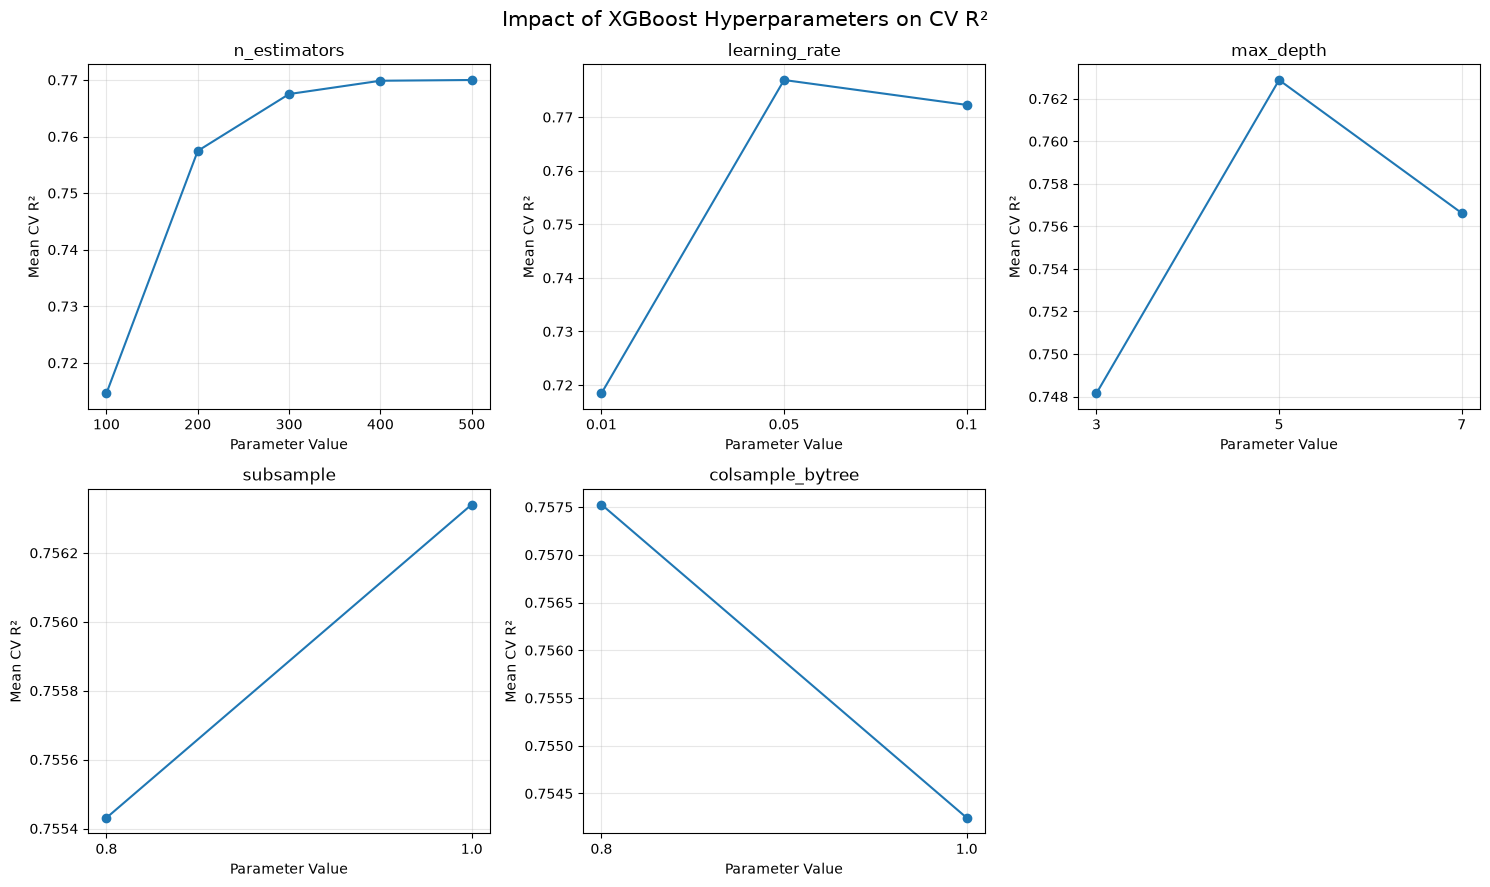

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# Lấy kết quả từ RandomizedSearchCV
df_cv = pd.DataFrame(search.cv_results_)

# Danh sách hyperparameters
params = [
    "param_n_estimators",
    "param_learning_rate",
    "param_max_depth",
    "param_subsample",
    "param_colsample_bytree"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, param in enumerate(params):

    # Tính R² trung bình theo từng giá trị parameter
    data = df_cv.groupby(param)["mean_test_r2"].mean()

    # Vẽ biểu đồ
    axes[i].plot(
        data.index.astype(str),
        data.values,
        marker="o"
    )

    axes[i].set_title(param.replace("param_", ""))
    axes[i].set_xlabel("Parameter Value")
    axes[i].set_ylabel("Mean CV R²")
    axes[i].grid(True, alpha=0.3)

# Xóa biểu đồ thứ 6 không sử dụng
fig.delaxes(axes[5])

plt.suptitle(
    "Impact of XGBoost Hyperparameters on CV R²",
    fontsize=15
)

plt.tight_layout()
plt.show()

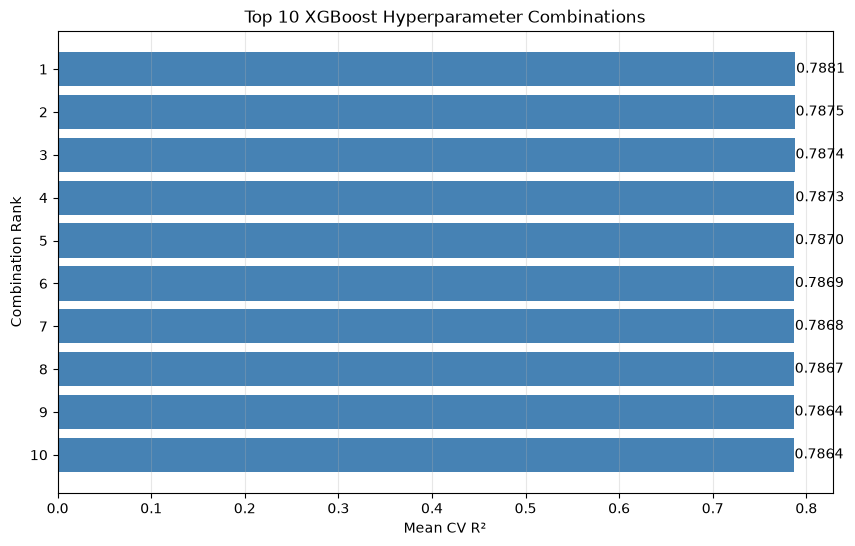

,Rank,param_n_estimators,param_learning_rate,param_max_depth,param_subsample,param_colsample_bytree,mean_test_r2
38,1,500,0.05,3,0.8,0.8,0.788092
45,2,300,0.05,5,1.0,0.8,0.787523
73,3,200,0.10,5,1.0,0.8,0.787416
47,4,400,0.05,5,1.0,0.8,0.787323
44,5,300,0.05,5,0.8,0.8,0.787011
64,6,300,0.10,3,0.8,0.8,0.786851
49,7,500,0.05,5,1.0,0.8,0.786828
154,8,300,0.10,3,0.8,1.0,0.786663
42,9,200,0.05,5,0.8,0.8,0.786400
71,10,100,0.10,5,1.0,0.8,0.786398


In [18]:
import pandas as pd
import matplotlib.pyplot as plt

# Lấy kết quả tuning
df_cv = pd.DataFrame(search.cv_results_)

# Chọn 10 tổ hợp có CV R² cao nhất
top10 = df_cv.sort_values(
    by="mean_test_r2",
    ascending=False
).head(10).copy()

# Đánh số thứ hạng
top10["Rank"] = range(1, 11)

# Vẽ biểu đồ
plt.figure(figsize=(10, 6))

bars = plt.barh(
    top10["Rank"].astype(str),
    top10["mean_test_r2"],
    color="steelblue"
)

# Hiển thị R² trên mỗi cột
for bar in bars:
    plt.text(
        bar.get_width() + 0.001,
        bar.get_y() + bar.get_height()/2,
        f"{bar.get_width():.4f}",
        va="center"
    )

plt.gca().invert_yaxis()
plt.xlim(0, max(top10["mean_test_r2"]) + 0.04)
plt.xlabel("Mean CV R²")
plt.ylabel("Combination Rank")
plt.title("Top 10 XGBoost Hyperparameter Combinations")
plt.grid(axis="x", alpha=0.3)

plt.show()

# Hiển thị chi tiết các tổ hợp
display(top10[[
    "Rank",
    "param_n_estimators",
    "param_learning_rate",
    "param_max_depth",
    "param_subsample",
    "param_colsample_bytree",
    "mean_test_r2"
]])

In [19]:
idx = search.best_index_
cv = search.cv_results_

tuned_result = pd.DataFrame([{
    "Model": "XGBoost (Tuned)",
    "Train R²": cv["mean_train_r2"][idx],
    "CV R²": cv["mean_test_r2"][idx],
    "CV MAE": -cv["mean_test_mae"][idx],
    "CV RMSE": -cv["mean_test_rmse"][idx]
}])

display(tuned_result.round(4))

,Model,Train R²,CV R²,CV MAE,CV RMSE
0,XGBoost (Tuned),0.8384,0.7881,0.2902,0.3738


In [20]:
comparison = pd.concat(
    [baseline_results, tuned_result],
    ignore_index=True
)

display(
    comparison.sort_values(
        "CV R²",
        ascending=False
    ).round(4)
)

,Model,Train R²,CV R²,CV MAE,CV RMSE
2,XGBoost (Tuned),0.8384,0.7881,0.2902,0.3738
0,Linear Regression,0.7829,0.7760,0.3014,0.3845
1,XGBoost,0.9170,0.7609,0.3077,0.3971


In [21]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
import numpy as np

# Lấy mô hình tốt nhất
best_xgb = search.best_estimator_

# Dự đoán trên tập Test
y_pred = best_xgb.predict(X_test)

# Đánh giá trên thang log
print("Test R²:", r2_score(y_test, y_pred))
print("Test MAE:", mean_absolute_error(y_test, y_pred))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

Test R²: 0.7982072513990521
Test MAE: 0.2893168070757848
Test RMSE: 0.3719843674549322


In [22]:
# Chuyển từ log về giá xe gốc
y_test_real = np.expm1(y_test)
y_pred_real = np.expm1(y_pred)

print("Test MAE (INR):", mean_absolute_error(y_test_real, y_pred_real))
print("Test RMSE (INR):", np.sqrt(
    mean_squared_error(y_test_real, y_pred_real)
))

Test MAE (INR): 140910.52137526186
Test RMSE (INR): 334868.7861822036
